c:\anaconda\envs\ML_basic\lib\site-packages\torchvision\io\image.py:13: UserWarning: Failed to load image Python extension: '[WinError 127] Die angegebene Prozedur wurde nicht gefunden'If you don't plan on using image functionality from `torchvision.io`, you can ignore this warning. Otherwise, there might be something wrong with your environment. Did you have `libjpeg` or `libpng` installed before building `torchvision` from source?
  warn(


##################################################################

Test set: Avg. loss: 2.3966, Accuracy: 1044/10000 (10%)

##################################################################
[Train Epoch:  1]   [samples: ---64/60000 (  0%)]   [Loss: 2.4505]
[Train Epoch:  1]   [samples: -2112/60000 (  4%)]   [Loss: 2.2512]
[Train Epoch:  1]   [samples: -4160/60000 (  7%)]   [Loss: 2.2453]
[Train Epoch:  1]   [samples: -6208/60000 ( 10%)]   [Loss: 2.1753]
[Train Epoch:  1]   [samples: -8256/60000 ( 14%)]   [Loss: 1.9441]
[Train Epoch:  1]   [samples: 10304/60000 ( 17%)]   [Loss: 1.7764]
[Train Epoch:  1]   [samples: 12352/60000 ( 21%)]   [Loss: 1.7753]
[Train Epoch:  1]   [samples: 14400/60000 ( 24%)]   [Loss: 1.6675]
[Train Epoch:  1]   [samples: 16448/60000 ( 27%)]   [Loss: 1.8274]
[Train Epoch:  1]   [samples: 18496/60000 ( 31%)]   [Loss: 1.5386]
[Train Epoch:  1]   [samples: 20544/60000 ( 34%)]   [Loss: 1.2686]
[Train Epoch:  1]   [samples: 22592/60000 ( 38%)]   [Loss: 1.1856]
[Tra

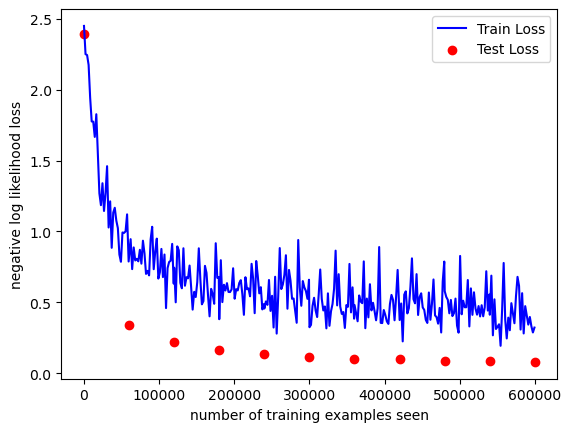

In [1]:
# [Imports] ############################################################################################################
import os
import sys
import time
import datetime
import copy

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torch.utils.data as data
import torchvision
import torchvision.datasets as datasets

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import LightSource
import scipy


# [Parameter and Convenience] ##########################################################################################
n_epochs         = 10
batch_size_train = 64
batch_size_test  = 100
learning_rate    = 0.01
momentum         = 0.5
log_interval     = 32


# [Function Definitions] ###############################################################################################
def show_examples(loader):
    examples = enumerate(loader)
    batch_idx, (example_data, example_lables) = next(examples) # takes first element off the iterator. (1st batch)
    print("Data Size:", example_data.size())
    print("Batch no.:", batch_idx)


    fig = plt.figure()
    for i in range(8):
        plt.subplot(2,4,i+1)
        plt.tight_layout()
        plt.imshow(example_data[i][0], cmap='gray', interpolation='none')
        plt.title("Ground Truth: {}".format(example_lables[i]))
        plt.xticks([])
        plt.yticks([])

def print_train_info():

    percent         = 100. * (batch_idx+1) / len(train_loader)
    tot_samples     = len(train_loader.dataset)
    current_samples = (batch_idx+1) * batch_size_train
    print(f"[Train Epoch: {E:>2}]", end="   ")
    print(f"[samples: {current_samples:->5}/{tot_samples} ({percent:>3.0f}%)]", end="   ")
    print(f"[Loss: {loss.item():.4f}]")

    return

def do_epoch_evaluation():
    
    test_loss = 0
    correct   = 0
    
    for data_batch, label in test_loader:
        # calculate the loss over the whole validation set and store it
        prediction = net1(data_batch)
        test_loss += loss_function(prediction, label, reduction="sum") # sum up all losses for all samples
        label_prediction = prediction.data.max(1, keepdim=True)[1] # getting the actual most likely labels
        correct += label_prediction.eq(label.data.view_as(label_prediction)).sum() # get nr of correct labels
    test_loss /= len(test_loader.dataset)
    test_losses.append(test_loss)  
    
    print("##################################################################")
    print('\nTest set: Avg. loss: {:.4f}, Accuracy: {}/{} ({:.0f}%)\n'.format(
        test_loss, correct, len(test_loader.dataset),
        100. * correct / len(test_loader.dataset)))
    print("##################################################################")

    return

def plot_info_graph():
    
    fig = plt.figure()
    plt.plot(train_counter, train_losses, color='blue')
    plt.scatter(test_counter, test_losses, color='red')
    plt.legend(['Train Loss', 'Test Loss'], loc='upper right')
    plt.xlabel('number of training examples seen')
    plt.ylabel('negative log likelihood loss')    
    
    return


# [Class Definitions] ##################################################################################################
class My_MNIST_net(nn.Module):
    def __init__(self):
        super().__init__()
        
        # define layers
        self.conv1      = nn.Conv2d( 1, 10, kernel_size=5, stride=1) # conv.  1->10 channels, 5x5 filter
        self.conv2      = nn.Conv2d(10, 20, kernel_size=5, stride=1) # conv. 10->20 channels, 5x5 filter
        self.conv_drop  = nn.Dropout2d(p=0.7)                        # randomly zero out entire channels
        self.fc1        = nn.Linear(320, 50)                         # fully connected layer
        self.fctest     = nn.Linear( 50, 50)                         # just for testing
        self.fc2        = nn.Linear( 50, 10)                         # fully connected layer
        self.fc_drop    = nn.Dropout(p=0.7)                          # randomly zero out neurons
        
    def forward(self, x):
        # INPUT: 1x28x28 images (one channel, 28x28 pixels)
        x = self.conv1(x)                          # -> 10x24x24
        x = F.relu(F.max_pool2d(x, kernel_size=2)) # -> 10x12x12
        x = self.conv_drop(self.conv2(x))          # -> 20 x8 x8
        x = F.relu(F.max_pool2d(x, kernel_size=2)) # -> 20 x4 x4
        x = x.view(-1, 320)                        # -> 1x320
        x = F.relu(self.fc1(x))                    # -> 1 x50
        x = self.fc_drop(x) 
        x = self.fc2(x)                            # -> 1 x10 (one hot)
        x = F.log_softmax(x, dim=1)
        return x
    

# [Do Work] ############################################################################################################

# Import Data ----------------------------------------------------------------------------------------------------------
# note, normally, this could also be done from csv files or something similar. Dataset is a class for a bit more "intricate" datasets. If not necessary, the raw data can just be loaded into a Dataloader Object. This is ultimately just an iterable for the Net and it's convenient to change shuffling, splits, etc...
train_loader = torch.utils.data.DataLoader(
    torchvision.datasets.MNIST(
        '/files/', 
        train=True, 
        download=True, 
        transform=torchvision.transforms.Compose(
            [torchvision.transforms.ToTensor(), torchvision.transforms.Normalize((0.1307,), (0.3081,))])),
    batch_size=batch_size_train, 
    shuffle=True)

test_loader = torch.utils.data.DataLoader(
    torchvision.datasets.MNIST(
        '/files/',
        train=False, 
        download=True,
        transform=torchvision.transforms.Compose(
            [torchvision.transforms.ToTensor(), torchvision.transforms.Normalize((0.1307,), (0.3081,))])),
    batch_size=batch_size_test, 
    shuffle=False)

# build network --------------------------------------------------------------------------------------------------------
net1            = My_MNIST_net()
optimizer       = optim.SGD(net1.parameters(), lr=learning_rate, momentum=momentum)
loss_function   = F.nll_loss

train_losses  = [] # track all training losses (Batch iteration)
train_counter = [] # (optional) tracks number of training samples seen (for plot)
test_losses   = [] # tracks all validation losses (Epoch iteration)
test_counter  = [i*len(train_loader.dataset) for i in range(n_epochs + 1)] # (opt) track nr of samples seen @ validation

# initial network evaluation
with torch.no_grad():
    do_epoch_evaluation()

# main loop iterate over EPOCHS ----------------------------------------------------------------------------------------
for E in range(1, n_epochs+1):
    net1.train()
    
    # loop through one whole BATCH -------------------------------------------------------------------------------------
    for batch_idx, (data_batch, label) in enumerate(train_loader):
        prediction = net1(data_batch)
        loss = loss_function(prediction, label) 
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        # logging every log_interval steps
        if batch_idx % log_interval == 0:
            # console output
            print_train_info()
            # saving training loss to list
            train_losses.append(loss.item()) #.item(): just the value of loss (alt. no_grad, but can't be used here?)
            train_counter.append(((batch_idx+1)*64) + ((E-1)*len(train_loader.dataset)))
    
    net1.eval()
    with torch.no_grad():
        do_epoch_evaluation()
    
plot_info_graph() 
    

In [2]:
# analyze network and get PARAM LIST
for name, param in net1.named_parameters():
    if param.requires_grad:
        print(f"Name:  {name:<14} {param.data.size()}")

# Save network Parameters. get parameters (all of them)
params_optimal = []
for el in net1.parameters():
    params_optimal.append(el.data) # this (.data) acutally only takes the tensor and discards the object or whatever
    # print(el.size())

# backup parameters
params_optimal_BACKUP = copy.deepcopy(params_optimal)

Name:  conv1.weight   torch.Size([10, 1, 5, 5])
Name:  conv1.bias     torch.Size([10])
Name:  conv2.weight   torch.Size([20, 10, 5, 5])
Name:  conv2.bias     torch.Size([20])
Name:  fc1.weight     torch.Size([50, 320])
Name:  fc1.bias       torch.Size([50])
Name:  fctest.weight  torch.Size([50, 50])
Name:  fctest.bias    torch.Size([50])
Name:  fc2.weight     torch.Size([10, 50])
Name:  fc2.bias       torch.Size([10])


In [ ]:
# Reset parameters of the Optimally trained net
for i, param in enumerate(net1.parameters()):
    param.data = params_optimal_BACKUP[i]

In [7]:
num_batches_for_loss_calc = 2 # batch size 100, 100*100 = 10'000 is max

S       = 0.3   # scale stepsize for grid by S
k_range = 80  # of points
j_range = 80

do_trainmode = True # the real one WITHOUT dropout, etc
do_evalmode  = True  # contains some stuff that is usually only active during training

nr_calcs = k_range * j_range

def calc_eval_loss_evalmode(net, loss_function, test_loader, batch_lim):
    loss = 0
    
    net.eval()
    if batch_lim == 0:
        return loss
    with torch.no_grad():
        for batch_idx, (data_batch, label) in enumerate(test_loader):
            prediction = net(data_batch)
            loss += loss_function(prediction, label, reduction="sum")
            if (batch_idx+1) >= batch_lim:
                break   
        loss = loss / (batch_size_test*(batch_idx+1))
    
    return loss

def calc_eval_loss_trainmode(net, loss_function, test_loader, batch_lim):
    loss = 0
    
    net.train()
    if batch_lim == 0:
        return loss
    
    for batch_idx, (data_batch, label) in enumerate(test_loader):
        prediction = net(data_batch)
        loss += loss_function(prediction, label, reduction="sum")
        if (batch_idx+1) >= batch_lim:
            break   
    loss = loss / (batch_size_test*(batch_idx+1))
    
    return loss

def print_progress(counter, nr_calcs):
    character = "#"
    perc = 100*counter/nr_calcs # percent progress
    print(f"Creating Loss map:      calculation progress [{counter}/{nr_calcs}] ", end="")
    print(f"[{perc:.0f}%] [{character*round(0.5*perc):-<50}]", end="\r")  #  [{"#"*round(0.1*perc):<10}]
    return

# generate the Random Direction(s) in parameter space of model
random_dir_1 = []
random_dir_2 = []
square_sum_1 = 0
square_sum_2 = 0

for i, el in enumerate(params_optimal):
    size = el.size()
    randomtensor_1 = torch.rand(size) - 0.5*torch.ones(size) # random direction, positive and negative rand is € [0, 1)
    randomtensor_2 = torch.rand(size) - 0.5*torch.ones(size)
    random_dir_1.append(randomtensor_1)
    random_dir_2.append(randomtensor_2)
    square_sum_1 += torch.sum(torch.square(randomtensor_1))
    square_sum_2 += torch.sum(torch.square(randomtensor_2))
# normalize the whole "direction" vector + Scale it with the factor S  
for i, el in enumerate(random_dir_1):
    random_dir_1[i] /= np.sqrt(square_sum_1)
    random_dir_2[i] /= np.sqrt(square_sum_2)
    random_dir_1[i] *= S
    random_dir_2[i] *= S
   
   
# iterate through all datapoints    
loss_mtx_trainmode = np.zeros((k_range, j_range))
loss_mtx_evalmode  = np.zeros((k_range, j_range))

# do loss calculation loop once for trainmode ...
if do_trainmode:
    counter = 0
    for j in range(j_range):
        for k in range(k_range):
            # incrementally update net parameters
            for i, param in enumerate(net1.parameters()):
                k_offset = (k_range-1)/2*random_dir_1[i]
                j_offset = (j_range-1)/2*random_dir_2[i]
                param.data = params_optimal[i] - k_offset - j_offset + k*random_dir_1[i] + j*random_dir_2[i] 
            # claculate loss @ k, j in parameter space slice
            loss = calc_eval_loss_trainmode(net1, loss_function, test_loader, num_batches_for_loss_calc)
            loss_mtx_trainmode[k, j] = loss
            counter += 1
            print_progress(counter, nr_calcs)

print()        
# ... and the same thing for evalmode 
if do_evalmode:
    counter = 0
    for j in range(j_range):
        for k in range(k_range):
            # incrementally update net parameters
            for i, param in enumerate(net1.parameters()):
                k_offset = (k_range-1)/2*random_dir_1[i]
                j_offset = (j_range-1)/2*random_dir_2[i]
                param.data = params_optimal[i] - k_offset - j_offset + k*random_dir_1[i] + j*random_dir_2[i] 
            # claculate loss @ k, j in parameter space slice
            loss = calc_eval_loss_evalmode(net1, loss_function, test_loader, num_batches_for_loss_calc)
            loss_mtx_evalmode[k, j] = loss
            counter += 1
            print_progress(counter, nr_calcs)


Creating Loss map:      calculation progress [6400/6400] [100%] [##################################################]


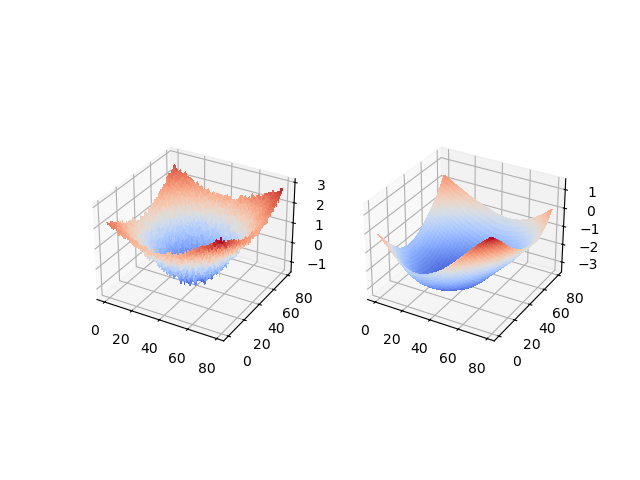

In [8]:
%matplotlib widget

X = np.linspace(0, k_range -1, k_range)
Y = np.linspace(0, j_range -1, j_range)
X, Y = np.meshgrid(X, Y)

fig, ax = plt.subplots(1, 2, subplot_kw={"projection": "3d"})
surf = ax[0].plot_surface(X, Y, np.log(loss_mtx_trainmode), cmap=cm.coolwarm, linewidth=0, antialiased=False)
surf = ax[1].plot_surface(X, Y, np.log(loss_mtx_evalmode), cmap=cm.coolwarm, linewidth=0, antialiased=False)

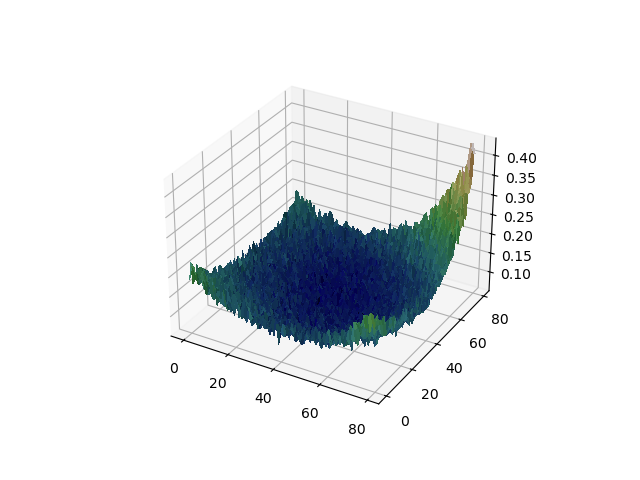

In [ ]:
fig, ax = plt.subplots(subplot_kw=dict(projection='3d'))
ls = LightSource(270, 45)

rgb = ls.shade(loss_mtx, cmap=cm.gist_earth, vert_exag=0.1, blend_mode='soft')
surf = ax.plot_surface(X, Y, loss_mtx, rstride=1, cstride=1, facecolors=rgb,
                       linewidth=0, antialiased=False, shade=True)


In [ ]:
# plot filters
layer_1 = params_optimal[0]

for i, el in enumerate(layer_1):
    plt.subplot(2, 5, i+1)
    plt.tight_layout()
    plt.imshow(el[0], cmap="gray", interpolation="none")

# fig = plt.figure()
# plt.imshow(aaa, cmap="gray", interpolation="none")


# fig = plt.figure()
# for i in range(8):
#     plt.subplot(2,4,i+1)
#     plt.tight_layout()
#     plt.imshow(example_data[i][0], cmap='gray', interpolation='none')
#     plt.title("Ground Truth: {}".format(example_lables[i]))
#     plt.xticks([])
#     plt.yticks([])
